In [3]:
import pandas as pd
import numpy as np



In [4]:
predictions = pd.read_csv("test_predictions.csv")

metrics = pd.read_csv("model_metrics.csv")

In [5]:

print("Dataset Shape:", predictions.shape)

print("\nColumn Names:")
print(predictions.columns.tolist())

print("\nFirst 5 Records:")
display(predictions.head())

print("\nExisting Model Metrics:")
display(metrics)


Dataset Shape: (14175, 12)

Column Names:
['target_date', 'city_name', 'rain_next_day_mm', 'Persistence', 'City-month average', 'Ridge', 'KNN', 'Decision tree', 'Random forest', 'Extra trees', 'Histogram boosting', 'Voting ensemble']

First 5 Records:


,target_date,city_name,rain_next_day_mm,Persistence,City-month average,Ridge,KNN,Decision tree,Random forest,Extra trees,Histogram boosting,Voting ensemble
0,2023-01-01,Colombo,0.0,0.0,2.615423,1.998528,0.482698,0.906647,0.829717,0.651709,0.551739,0.601724
1,2023-01-02,Colombo,0.0,0.0,2.615423,1.595274,0.361122,0.902148,0.437788,0.500317,0.513608,0.506963
2,2023-01-03,Colombo,0.1,0.0,2.615423,2.574919,0.650594,0.902148,0.535816,0.918024,1.038505,0.978264
3,2023-01-04,Colombo,0.0,0.1,2.615423,1.594322,0.547961,1.122110,1.010583,1.130831,0.809490,0.970161
4,2023-01-05,Colombo,1.2,0.0,2.615423,1.335399,0.528342,0.906647,0.662897,0.475195,0.409572,0.442383



Existing Model Metrics:


,model,RMSE_mm,MAE_mm,R2,Validation_RMSE_mm,Validation_MAE_mm,Validation_R2
0,Persistence,9.073298,4.836642,0.119353,NaN,NaN,NaN
1,City-month average,8.719368,5.186807,0.186717,NaN,NaN,NaN
2,Ridge,7.748536,4.417308,0.357740,7.224378,4.355797,0.264826
3,KNN,7.729915,4.355691,0.360823,7.366812,4.291087,0.235552
4,Decision tree,7.938003,4.488221,0.325947,7.612313,4.437120,0.183752
5,Random forest,7.661290,4.366225,0.372122,7.390466,4.341977,0.230635
6,Extra trees,7.647822,4.346239,0.374327,7.335877,4.275050,0.241958
7,Histogram boosting,7.724140,4.378045,0.361778,7.370097,4.288784,0.234870
8,Voting ensemble,7.650026,4.346046,0.373967,7.311406,4.267032,0.247007


In [6]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Actual rainfall values
y_true = predictions["rain_next_day_mm"]

# Model prediction columns
model_names = [
    "Persistence",
    "City-month average",
    "Ridge",
    "KNN",
    "Decision tree",
    "Random forest",
    "Extra trees",
    "Histogram boosting",
    "Voting ensemble"
]

results = []

# Evaluate every model
for model in model_names:

    y_pred = predictions[model]

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Model": model,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

evaluation_df = pd.DataFrame(results)

# Rank models by test RMSE for analysis
evaluation_df = evaluation_df.sort_values("RMSE")

display(evaluation_df.round(4))


,Model,MAE,MSE,RMSE,R2
6,Extra trees,4.3462,58.4892,7.6478,0.3743
8,Voting ensemble,4.3460,58.5229,7.6500,0.3740
5,Random forest,4.3662,58.6954,7.6613,0.3721
7,Histogram boosting,4.3780,59.6623,7.7241,0.3618
3,KNN,4.3557,59.7516,7.7299,0.3608
2,Ridge,4.4173,60.0398,7.7485,0.3577
4,Decision tree,4.4882,63.0119,7.9380,0.3259
1,City-month average,5.1868,76.0274,8.7194,0.1867
0,Persistence,4.8366,82.3247,9.0733,0.1194


In [7]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Actual rainfall values
y_true = predictions["rain_next_day_mm"]

# Model prediction columns
model_names = [
    "Persistence",
    "City-month average",
    "Ridge",
    "KNN",
    "Decision tree",
    "Random forest",
    "Extra trees",
    "Histogram boosting",
    "Voting ensemble"
]

results = []

# Evaluate every model
for model in model_names:

    y_pred = predictions[model]

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Model": model,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

evaluation_df = pd.DataFrame(results)

# Rank models by test RMSE for analysis
evaluation_df = evaluation_df.sort_values("RMSE")

display(evaluation_df.round(4))


,Model,MAE,MSE,RMSE,R2
6,Extra trees,4.3462,58.4892,7.6478,0.3743
8,Voting ensemble,4.3460,58.5229,7.6500,0.3740
5,Random forest,4.3662,58.6954,7.6613,0.3721
7,Histogram boosting,4.3780,59.6623,7.7241,0.3618
3,KNN,4.3557,59.7516,7.7299,0.3608
2,Ridge,4.4173,60.0398,7.7485,0.3577
4,Decision tree,4.4882,63.0119,7.9380,0.3259
1,City-month average,5.1868,76.0274,8.7194,0.1867
0,Persistence,4.8366,82.3247,9.0733,0.1194


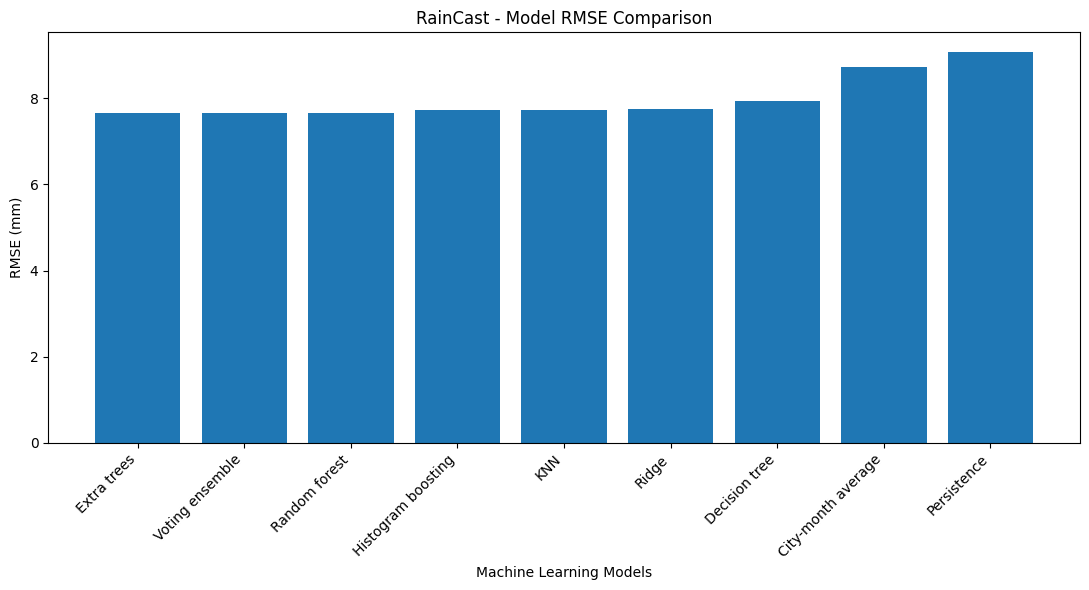

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    evaluation_df["Model"],
    evaluation_df["RMSE"]
)

plt.title("RainCast - Model RMSE Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE (mm)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


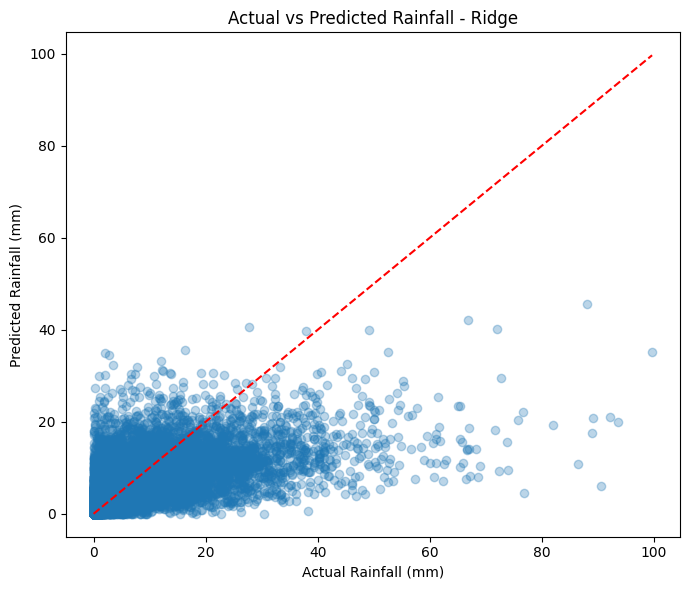

In [9]:

actual = predictions["rain_next_day_mm"]
predicted = predictions["Ridge"]

plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.3)

max_value = max(actual.max(), predicted.max())

plt.plot([0, max_value], [0, max_value], "r--")

plt.title("Actual vs Predicted Rainfall - Ridge")
plt.xlabel("Actual Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")

plt.tight_layout()
plt.show()


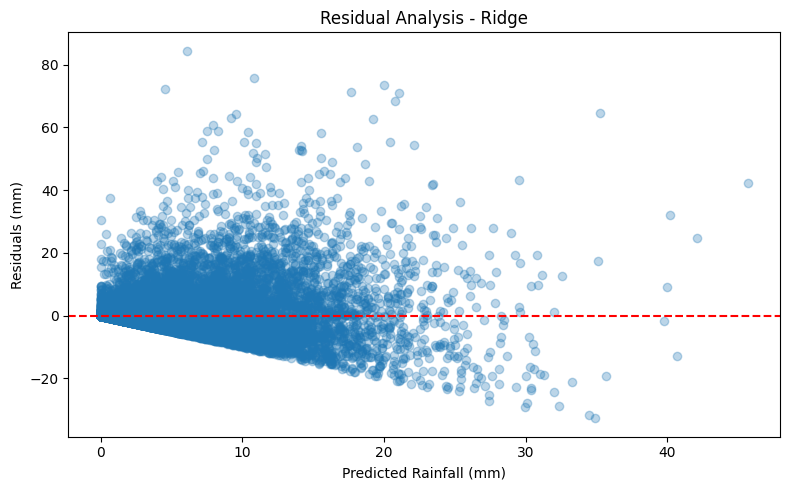

In [10]:

actual = predictions["rain_next_day_mm"]
predicted = predictions["Ridge"]

residuals = actual - predicted

plt.figure(figsize=(8, 5))

plt.scatter(predicted, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Analysis - Ridge")
plt.xlabel("Predicted Rainfall (mm)")
plt.ylabel("Residuals (mm)")

plt.tight_layout()
plt.show()


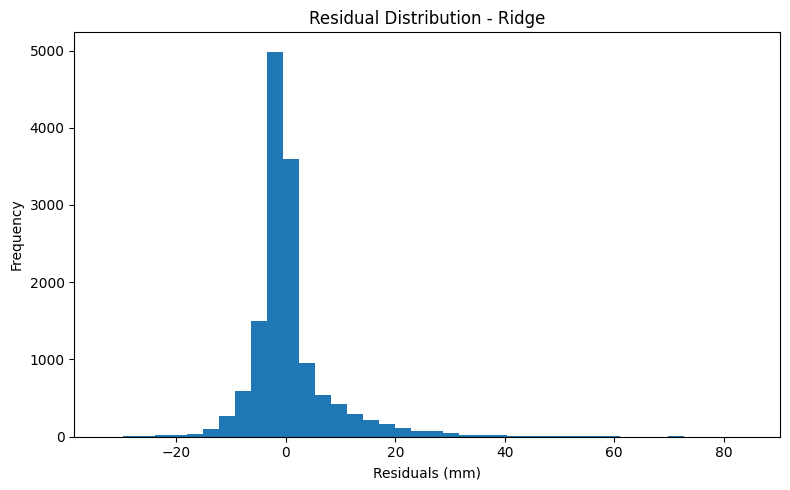

In [11]:

plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=40)

plt.title("Residual Distribution - Ridge")
plt.xlabel("Residuals (mm)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


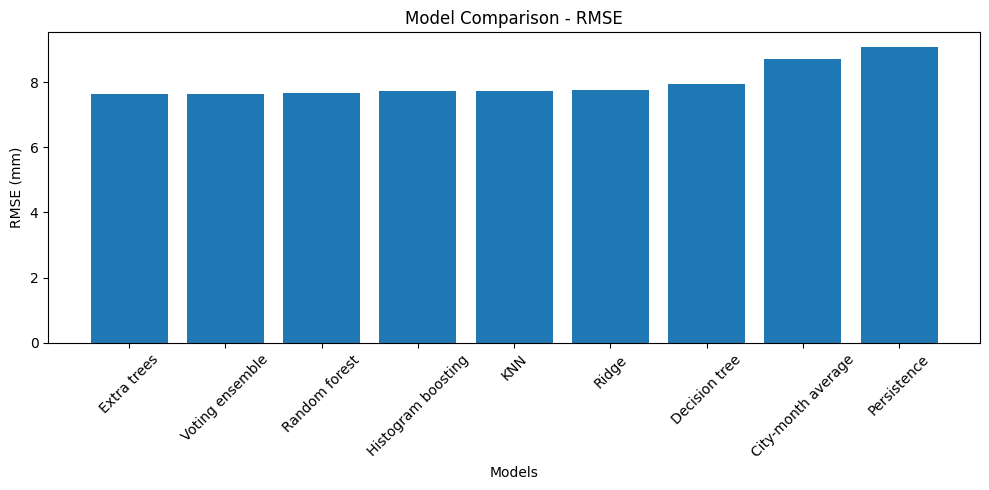

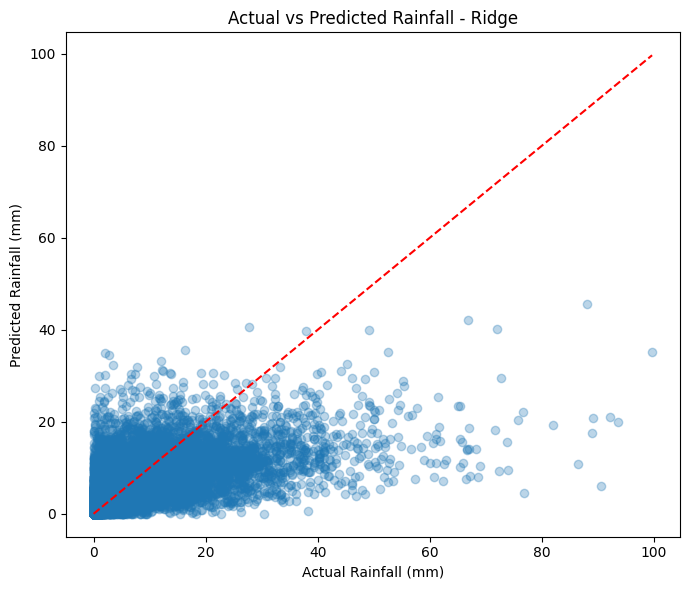

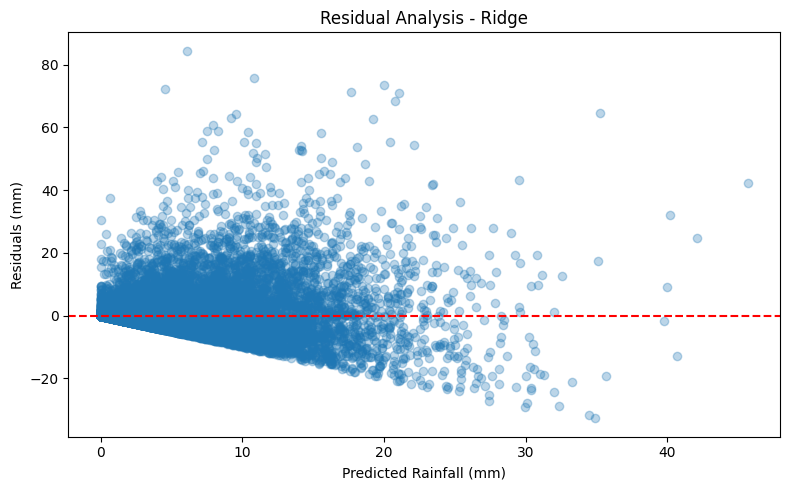

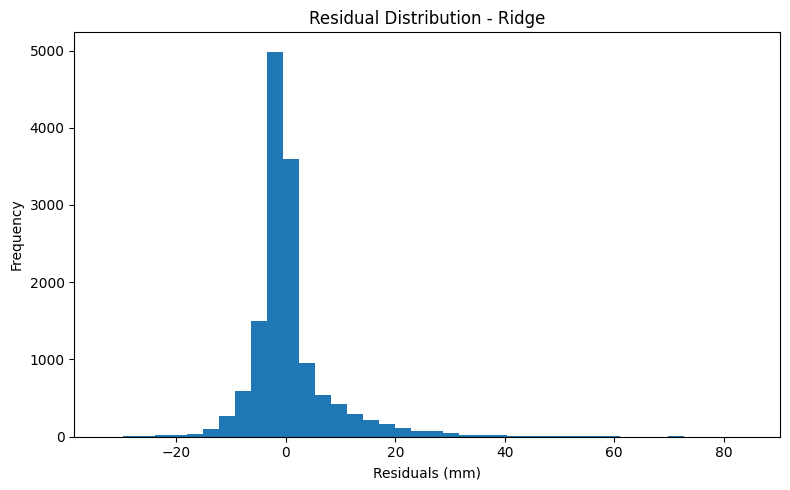

Evaluation results saved successfully!


In [12]:

import os

os.makedirs("evaluation", exist_ok=True)

# Save evaluation metrics
evaluation_df.to_csv(
    "evaluation/evaluation_metrics.csv",
    index=False
)

# Save RMSE comparison graph
plt.figure(figsize=(10, 5))
plt.bar(evaluation_df["Model"], evaluation_df["RMSE"])
plt.title("Model Comparison - RMSE")
plt.xlabel("Models")
plt.ylabel("RMSE (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("evaluation/model_comparison.png")
plt.show()

# Save actual vs predicted graph
plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.3)
plt.plot([0, max(actual.max(), predicted.max())],
         [0, max(actual.max(), predicted.max())], "r--")
plt.title("Actual vs Predicted Rainfall - Ridge")
plt.xlabel("Actual Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")
plt.tight_layout()
plt.savefig("evaluation/actual_vs_predicted.png")
plt.show()

# Save residual analysis graph
plt.figure(figsize=(8, 5))
plt.scatter(predicted, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")
plt.title("Residual Analysis - Ridge")
plt.xlabel("Predicted Rainfall (mm)")
plt.ylabel("Residuals (mm)")
plt.tight_layout()
plt.savefig("evaluation/residual_analysis.png")
plt.show()

# Save residual distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40)
plt.title("Residual Distribution - Ridge")
plt.xlabel("Residuals (mm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("evaluation/residual_distribution.png")
plt.show()

print("Evaluation results saved successfully!")


In [13]:

import shutil

shutil.make_archive(
    "rainfall_evaluation",
    "zip",
    "evaluation"
)

from google.colab import files
files.download("rainfall_evaluation.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>